In [1]:
#need to load lexicon manually here
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

lex_dir = "data/raw/opinion-lexicon-English/opinion-lexicon-English/"

def load_lexicon(path):
    with open(path, encoding="latin-1") as f:
        return {line.strip() for line in f if line.strip() and not line.startswith(";")}

pos_words = load_lexicon(lex_dir + "positive-words.txt")
neg_words = load_lexicon(lex_dir + "negative-words.txt")
print(len(pos_words), "positive words,", len(neg_words), "negative words")

2006 positive words, 4783 negative words


In [2]:
train = pd.read_csv("data/processed/train.csv")
test  = pd.read_csv("data/processed/test.csv")

X_test, y_test = test["text"], test["label"]
print(train.shape, test.shape)

(3659, 4) (915, 4)


In [3]:
negations = {"not", "no", "never", "don't", "doesn't", "didn't", "isn't", "wasn't",
             "aren't", "won't", "can't", "couldn't", "wouldn't", "shouldn't", "nothing", "hardly"}

def tokenize(text):
    return re.findall(r"[a-z0-9+'-]+", text.lower())

def lexicon_score(text, handle_negation=False):
    score, flip = 0, 0
    for word in tokenize(text):
        if handle_negation and word in negations:
            flip = 3
            continue
        value = (word in pos_words) - (word in neg_words)
        if flip > 0:
            value = -value
            flip -= 1
        score += value
    return score

def predict(texts, handle_negation=False):
    return ["negative" if lexicon_score(t, handle_negation) < 0 else "positive" for t in texts]

In [4]:
models = {
    "Word list": False,
    "Word list + negation": True,
}

results, preds = [], {}
for name, neg in models.items():
    y_pred = predict(X_test, handle_negation=neg)
    preds[name] = y_pred

    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    results.append({"model": name, "accuracy": accuracy_score(y_test, y_pred),
                    "precision": p, "recall": r, "f1": f1})
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3))

results_df = pd.DataFrame(results).round(3)
results_df

=== Word list ===
              precision    recall  f1-score   support

    negative      0.707     0.384     0.498       320
    positive      0.734     0.914     0.814       595

    accuracy                          0.729       915
   macro avg      0.721     0.649     0.656       915
weighted avg      0.725     0.729     0.704       915

=== Word list + negation ===
              precision    recall  f1-score   support

    negative      0.798     0.419     0.549       320
    positive      0.751     0.943     0.836       595

    accuracy                          0.760       915
   macro avg      0.774     0.681     0.693       915
weighted avg      0.767     0.760     0.736       915



,model,accuracy,precision,recall,f1
0,Word list,0.729,0.721,0.649,0.656
1,Word list + negation,0.760,0.774,0.681,0.693


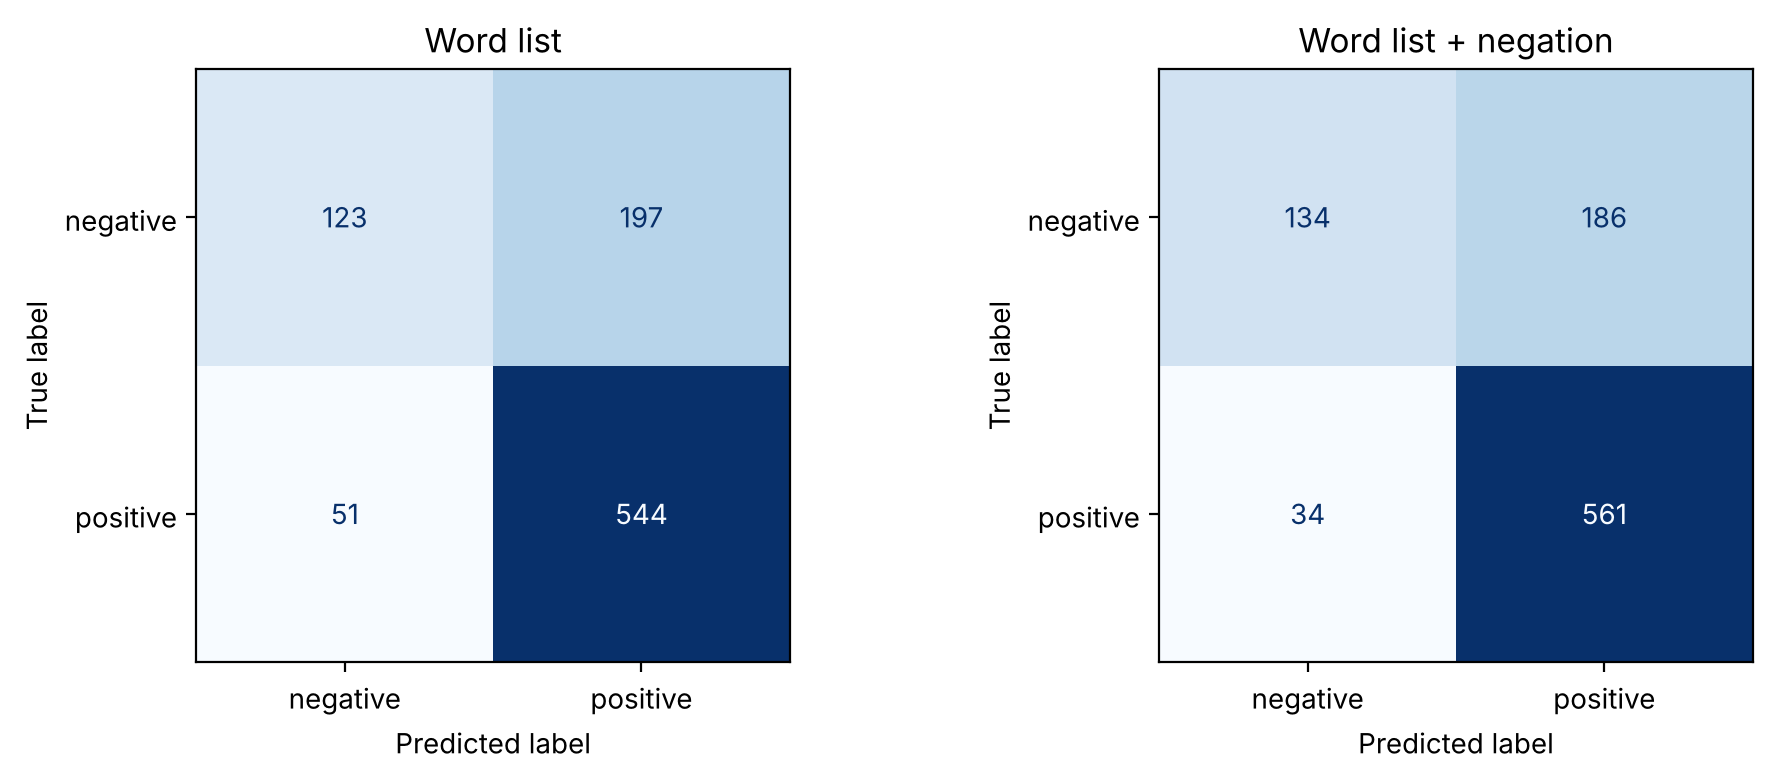

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [6]:
scores = X_test.apply(lexicon_score, handle_negation=True)
no_hits = (scores == 0).sum()
print(f"{no_hits} of {len(test)} test sentences have a net score of 0 (defaulted to positive)")

mistakes = test.assign(score=scores, pred=preds["Word list + negation"])
mistakes = mistakes[mistakes["label"] != mistakes["pred"]]
print(f"{len(mistakes)} wrong out of {len(test)}")
display(mistakes[["text", "label", "score", "pred"]].head(10))

results_df.to_csv("results_01.csv", index=False)

227 of 915 test sentences have a net score of 0 (defaulted to positive)
220 wrong out of 915


,text,label,score,pred
0,i built my own router table with a tilt up top...,negative,2,positive
3,"secondly, all info can be sent to a computer a...",positive,-1,negative
4,"since then, i have not found one major problem...",positive,-1,negative
5,the linksys technical support site has nothing...,negative,1,positive
8,) button sensitivity: even reduced to the lowe...,negative,2,positive
9,"i do not count this as a negative, however, be...",positive,-1,negative
15,the only downside to this is that it can get p...,negative,0,positive
21,"i 'm not easily impressed by electronics , ten...",positive,-2,negative
26,as a loyal customer of norton/symantec product...,negative,0,positive
27,this netbook is closer to the notebook powers ...,positive,-1,negative
